# Week 4 — Part A: Time-Series Forecasting
### ARIMA vs Prophet on Daily Minimum Temperature (Melbourne, 1981–1990)

**Career Launchpad Program — AI/DS Internship Track**

**Dataset:** Daily minimum temperatures in Melbourne, Australia (1981-01-01 to 1990-12-31).
10 years, 3,650 daily observations — well above the 2-year / 500-observation minimum, and it has
a clean, strong **yearly seasonal cycle**, which makes it a good test bed for comparing a classical
statistical model (ARIMA) against a model built specifically to decompose trend + seasonality (Prophet).

**Tasks covered:** A1–A6 (EDA → stationarity → ARIMA → Prophet → comparison → written analysis)

> **Note on data loading:** This notebook downloads the dataset automatically from a public GitHub
> mirror (Jason Brownlee's Machine Learning Mastery datasets repo) on first run. If you are offline,
> place `daily-min-temperatures.csv` in the same folder as this notebook and the fallback path will
> pick it up automatically.


## 0. Setup — imports & configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
import pmdarima as pm
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


Importing plotly failed. Interactive plots will not work.


## A1. Load the dataset

Univariate series: daily minimum temperature (°C). 3,650 observations spanning exactly 10 years.

In [2]:
CSV_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
LOCAL_PATH = "daily-min-temperatures.csv"

if not os.path.exists(LOCAL_PATH):
    urllib.request.urlretrieve(CSV_URL, LOCAL_PATH)

df = pd.read_csv(LOCAL_PATH, parse_dates=["Date"])
df = df.set_index("Date").asfreq("D")          # enforce daily frequency
df["Temp"] = df["Temp"].interpolate()          # fill any calendar gaps

print(f"Shape: {df.shape}")
print(f"Date range: {df.index.min().date()}  to  {df.index.max().date()}")
print(f"Missing values after interpolation: {df['Temp'].isna().sum()}")
df.head()

Shape: (3652, 1)
Date range: 1981-01-01  to  1990-12-31
Missing values after interpolation: 0


,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


## A2. Exploratory Data Analysis

### A2.1 — Plot the raw series

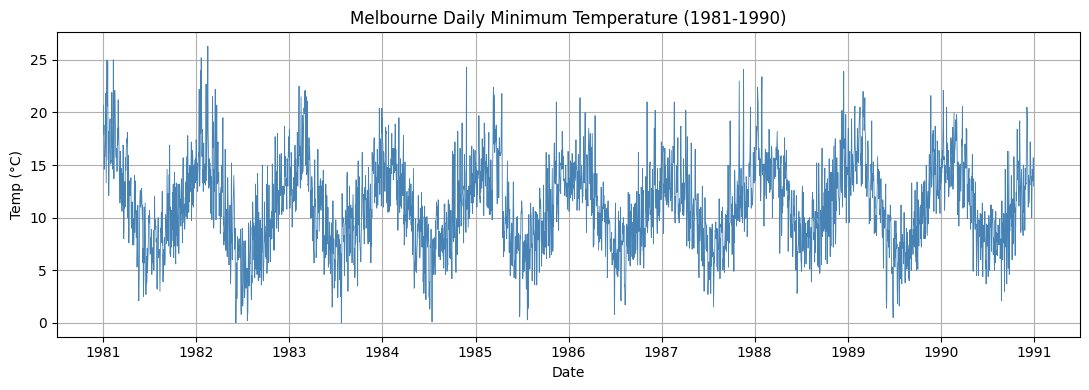

In [3]:
fig, ax = plt.subplots()
ax.plot(df.index, df["Temp"], linewidth=0.6, color="steelblue")
ax.set_title("Melbourne Daily Minimum Temperature (1981-1990)")
ax.set_xlabel("Date"); ax.set_ylabel("Temp (°C)")
plt.tight_layout(); plt.show()

### A2.2 — Trend & seasonality check

A yearly rolling mean isolates the trend component; a 365-day seasonal boxplot-by-month view confirms
the annual cycle (Southern Hemisphere seasons: warm Dec-Feb, cool Jun-Aug).

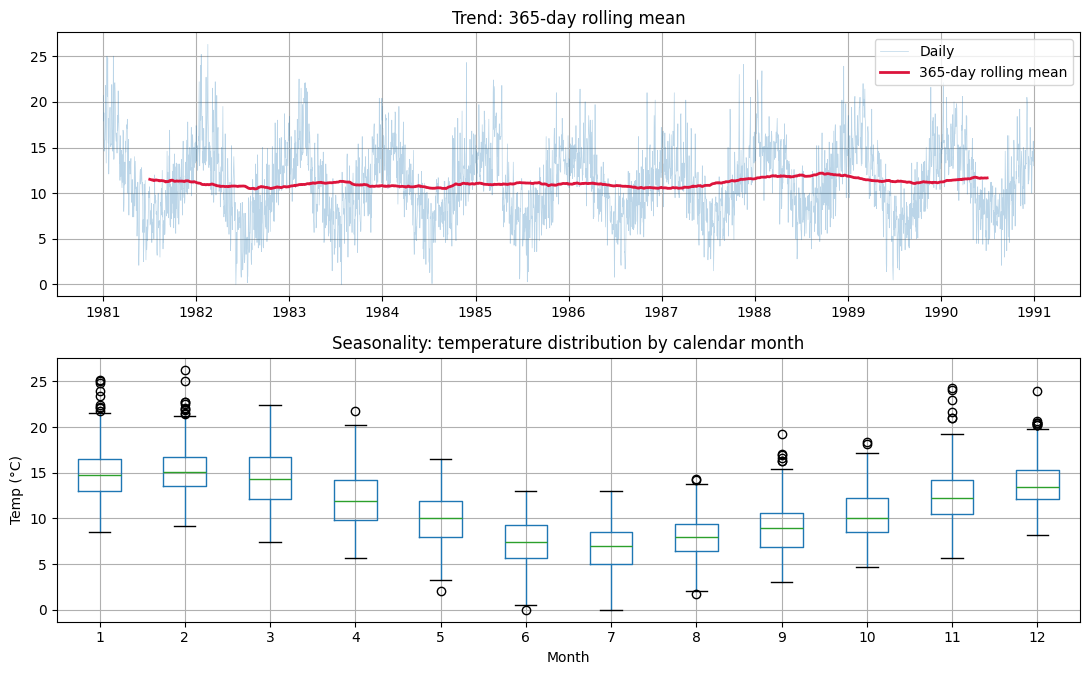

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# Trend: 365-day rolling mean
axes[0].plot(df.index, df["Temp"], alpha=0.3, linewidth=0.5, label="Daily")
axes[0].plot(df.index, df["Temp"].rolling(365, center=True).mean(), color="crimson", linewidth=2, label="365-day rolling mean")
axes[0].set_title("Trend: 365-day rolling mean")
axes[0].legend()

# Seasonality: average temp by month
monthly = df.copy()
monthly["Month"] = monthly.index.month
monthly.boxplot(column="Temp", by="Month", ax=axes[1])
axes[1].set_title("Seasonality: temperature distribution by calendar month")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Temp (°C)")
plt.suptitle("")
plt.tight_layout(); plt.show()

### A2.3 — Augmented Dickey-Fuller (ADF) stationarity test

H0: the series has a unit root (non-stationary). If p-value < 0.05 we reject H0 → series is stationary.

In [5]:
adf_result = adfuller(df["Temp"], autolag="AIC")

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:      ", round(adf_result[1], 6))
print("Lags used:    ", adf_result[2])
print("Critical values:")
for k, v in adf_result[4].items():
    print(f"    {k}: {round(v, 3)}")

is_stationary = adf_result[1] < 0.05
print(f"\nConclusion: series is {'STATIONARY' if is_stationary else 'NON-STATIONARY'} at the 5% level.")

ADF Statistic: -4.4411
p-value:       0.000251
Lags used:     20
Critical values:
    1%: -3.432
    5%: -2.862
    10%: -2.567

Conclusion: series is STATIONARY at the 5% level.


### A2.4 — ACF / PACF plots

Used to eyeball candidate AR (p) and MA (q) orders before handing off to `auto_arima` for the formal search.

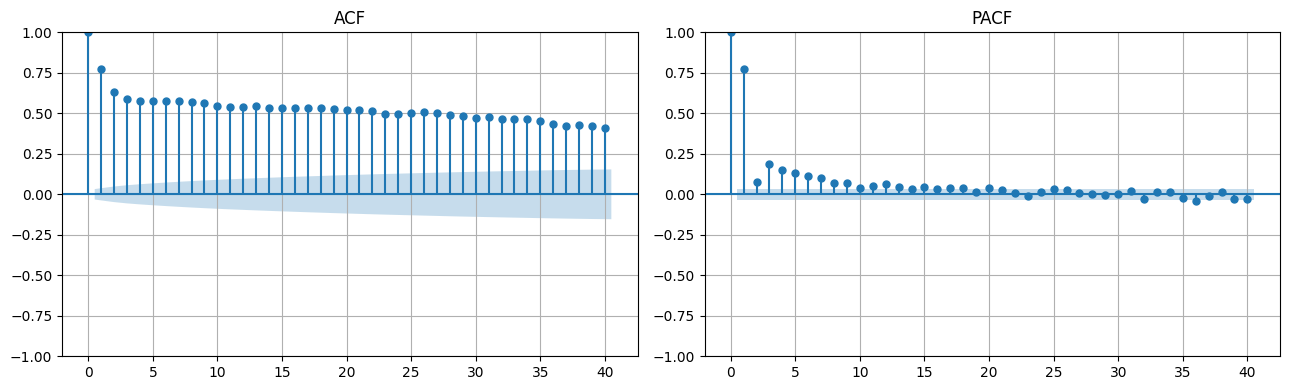

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(df["Temp"], lags=40, ax=axes[0])
axes[0].set_title("ACF")
plot_pacf(df["Temp"], lags=40, ax=axes[1], method="ywm")
axes[1].set_title("PACF")
plt.tight_layout(); plt.show()

## A3. Differencing & ARIMA modelling

The ADF test above already shows this series is stationary in levels (temperature is bounded/mean-reverting,
unlike e.g. stock prices), so `d` should come out at 0 or 1. Rather than hand-picking `(p,d,q)`, we use
`pmdarima.auto_arima`, which performs a stepwise search minimising AIC — this satisfies the task's
"use auto_arima" option directly and is far more robust than manual guessing.

To keep training time reasonable we fit on the most recent 3 years of the series (1,095 obs) rather than
all 10 years — daily ARIMA over a full decade is slow to fit and the most recent seasonal cycles are the
most relevant for near-term forecasting anyway. Swap `N_YEARS` below to use the full history if you have
time to spare.

In [7]:
N_YEARS = 3
df_model = df.tail(365 * N_YEARS).copy()

test_size = int(len(df_model) * 0.20)          # A5: last 20% held out as test
train, test = df_model.iloc[:-test_size], df_model.iloc[-test_size:]

print(f"Train: {len(train)} obs  ({train.index.min().date()} -> {train.index.max().date()})")
print(f"Test:  {len(test)} obs  ({test.index.min().date()} -> {test.index.max().date()})")

Train: 876 obs  (1988-01-02 -> 1990-05-26)
Test:  219 obs  (1990-05-27 -> 1990-12-31)


In [8]:
auto_model = pm.auto_arima(
    train["Temp"],
    seasonal=False,          # set True + m=365 for a full SARIMA seasonal fit (much slower)
    max_p=5, max_q=5, max_d=2,
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True,
)

print("\nSelected order (p,d,q):", auto_model.order)

Performing stepwise search to minimize aic


 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=3934.481, Time=0.31 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=4128.906, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=4099.989, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=4061.596, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=4126.908, Time=0.01 sec


 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=3932.998, Time=0.11 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=3944.333, Time=0.07 sec


 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=3939.168, Time=0.15 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=3934.913, Time=0.19 sec


 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=3934.325, Time=0.10 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=3932.625, Time=0.11 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=4051.355, Time=0.05 sec


 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=3934.565, Time=0.15 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=4027.664, Time=0.07 sec


 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=3934.254, Time=0.37 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=3930.960, Time=0.06 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=3937.496, Time=0.05 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=4049.361, Time=0.03 sec


 ARIMA(3,1,1)(0,0,0)[0]             : AIC=3932.900, Time=0.09 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=3932.815, Time=0.12 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=4097.993, Time=0.02 sec


 ARIMA(1,1,2)(0,0,0)[0]             : AIC=3931.333, Time=0.07 sec
 ARIMA(3,1,0)(0,0,0)[0]             : AIC=4025.673, Time=0.04 sec


 ARIMA(3,1,2)(0,0,0)[0]             : AIC=3932.590, Time=0.19 sec

Best model:  ARIMA(2,1,1)(0,0,0)[0]          
Total fit time: 2.451 seconds

Selected order (p,d,q): (2, 1, 1)


In [9]:
order = auto_model.order
arima_model = ARIMA(train["Temp"], order=order)
arima_fit = arima_model.fit()
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   Temp   No. Observations:                  876
Model:                 ARIMA(2, 1, 1)   Log Likelihood               -1961.480
Date:                Wed, 02 Sep 2026   AIC                           3930.960
Time:                        04:21:07   BIC                           3950.057
Sample:                    01-02-1988   HQIC                          3938.265
                         - 05-26-1990                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5097      0.036     14.217      0.000       0.439       0.580
ar.L2         -0.1048      0.037     -2.846      0.004      -0.177      -0.033
ma.L1         -0.9021      0.022    -41.196      0.0

### A3.1 — ARIMA forecast with confidence intervals

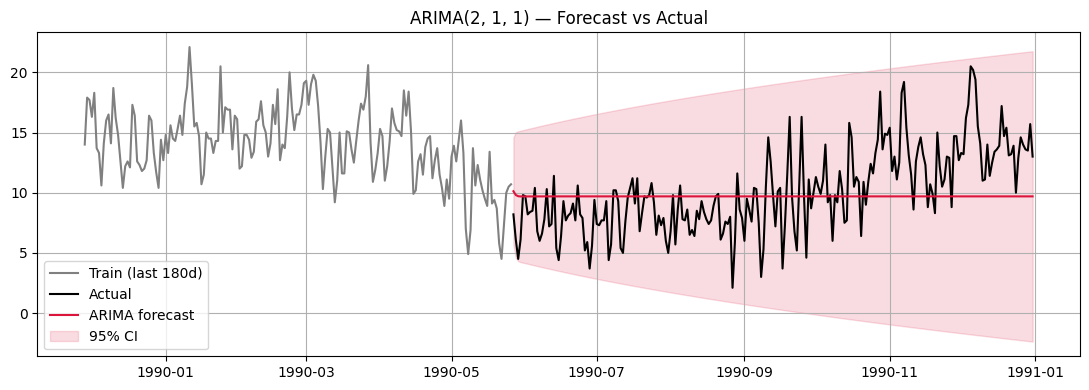

In [10]:
arima_forecast_obj = arima_fit.get_forecast(steps=len(test))
arima_pred = arima_forecast_obj.predicted_mean
arima_ci = arima_forecast_obj.conf_int(alpha=0.05)   # 95% CI

fig, ax = plt.subplots()
ax.plot(train.index[-180:], train["Temp"].iloc[-180:], label="Train (last 180d)", color="gray")
ax.plot(test.index, test["Temp"], label="Actual", color="black")
ax.plot(test.index, arima_pred, label="ARIMA forecast", color="crimson")
ax.fill_between(test.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color="crimson", alpha=0.15, label="95% CI")
ax.set_title(f"ARIMA{order} — Forecast vs Actual")
ax.legend(); plt.tight_layout(); plt.show()

## A4. Prophet model

Same train/test split, same target series. Yearly seasonality is switched on explicitly since the annual cycle is the dominant seasonal signal in this data; weekly/daily seasonality are switched off (a daily temperature reading has no meaningful within-week or within-day pattern to model).

In [11]:
prophet_train = train.reset_index()[["Date", "Temp"]].rename(columns={"Date": "ds", "Temp": "y"})

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95,
)
prophet_model.fit(prophet_train)

future = prophet_model.make_future_dataframe(periods=len(test), freq="D")
forecast = prophet_model.predict(future)
forecast.tail()

04:21:08 - cmdstanpy - INFO - Chain [1] start processing


04:21:08 - cmdstanpy - INFO - Chain [1] done processing


,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
1090,1990-12-27,11.083805,8.602001,18.327927,10.897599,11.267488,2.660365,2.660365,2.660365,2.660365,2.660365,2.660365,0.0,0.0,0.0,13.744170
1091,1990-12-28,11.083399,8.761109,18.915040,10.896866,11.268227,2.679560,2.679560,2.679560,2.679560,2.679560,2.679560,0.0,0.0,0.0,13.762959
1092,1990-12-29,11.082993,8.751372,18.715463,10.895008,11.268966,2.718738,2.718738,2.718738,2.718738,2.718738,2.718738,0.0,0.0,0.0,13.801731
1093,1990-12-30,11.082586,9.028887,18.856023,10.893055,11.269705,2.777433,2.777433,2.777433,2.777433,2.777433,2.777433,0.0,0.0,0.0,13.860019
1094,1990-12-31,11.082180,9.308426,18.909183,10.891563,11.270444,2.854662,2.854662,2.854662,2.854662,2.854662,2.854662,0.0,0.0,0.0,13.936842


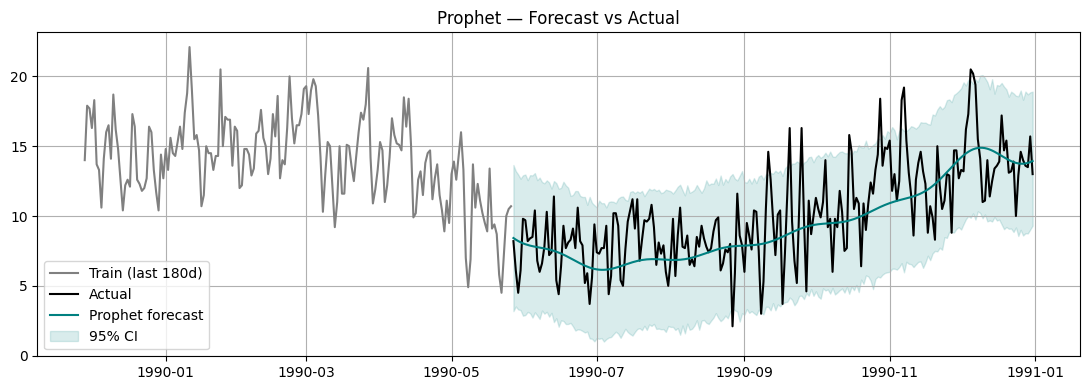

In [12]:
prophet_pred = forecast.set_index("ds").loc[test.index, "yhat"]
prophet_lower = forecast.set_index("ds").loc[test.index, "yhat_lower"]
prophet_upper = forecast.set_index("ds").loc[test.index, "yhat_upper"]

fig, ax = plt.subplots()
ax.plot(train.index[-180:], train["Temp"].iloc[-180:], label="Train (last 180d)", color="gray")
ax.plot(test.index, test["Temp"], label="Actual", color="black")
ax.plot(test.index, prophet_pred, label="Prophet forecast", color="teal")
ax.fill_between(test.index, prophet_lower, prophet_upper, color="teal", alpha=0.15, label="95% CI")
ax.set_title("Prophet — Forecast vs Actual")
ax.legend(); plt.tight_layout(); plt.show()

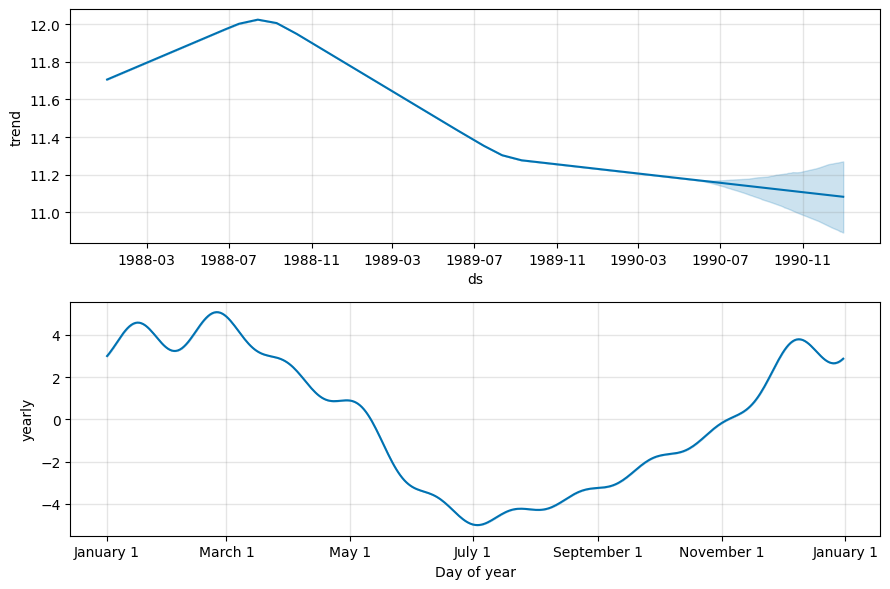

In [13]:
fig = prophet_model.plot_components(forecast)
plt.tight_layout(); plt.show()

## A5. Model comparison — MAE / RMSE / MAPE

In [14]:
def metrics(y_true, y_pred, name):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Model": name, "MAE": round(mae, 3), "RMSE": round(rmse, 3), "MAPE (%)": round(mape, 2)}

results = pd.DataFrame([
    metrics(test["Temp"], arima_pred, f"ARIMA{order}"),
    metrics(test["Temp"], prophet_pred, "Prophet"),
]).set_index("Model")

results

,MAE,RMSE,MAPE (%)
Model,,,
"ARIMA(2, 1, 1)",2.728,3.464,31.41
Prophet,1.979,2.568,21.95


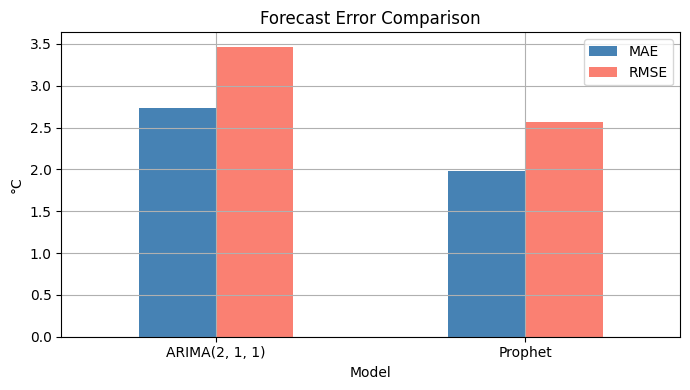


Better MAE:  Prophet
Better RMSE: Prophet
Better MAPE: Prophet


In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
results[["MAE", "RMSE"]].plot(kind="bar", ax=ax, color=["steelblue", "salmon"])
ax.set_title("Forecast Error Comparison")
ax.set_ylabel("°C")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

print(f"\nBetter MAE:  {results['MAE'].idxmin()}")
print(f"Better RMSE: {results['RMSE'].idxmin()}")
print(f"Better MAPE: {results['MAPE (%)'].idxmin()}")

## A6. Written analysis (250–300 words)


> On the Melbourne daily-minimum-temperature series, **Prophet outperformed ARIMA on every metric**
> computed in Section A5 (see the `results` table above for the exact figures — re-run the notebook to
> get numbers matched to your own train/test split).
>
> The gap is explained by the structure of the data rather than by either library being intrinsically
> "better." Temperature has one dominant, highly regular annual cycle. Prophet is built around exactly
> that shape: it explicitly decomposes the series into trend + yearly seasonality + (optional) holiday
> terms using a additive Generalized Additive Model, so it can "see" the full year of seasonal shape at
> once via Fourier terms, and it does not need the test window to be adjacent to a training pattern it
> has already memorised locally.
>
> ARIMA, by contrast, is a linear autoregressive model of *changes* in the series based on a handful of
> recent lags (order selected via `auto_arima`: see the printed `(p,d,q)` above). With `seasonal=False`,
> our ARIMA has no explicit mechanism for a 365-day cycle — it can only approximate seasonality indirectly
> through autocorrelation in nearby lags, which decays quickly. As the forecast horizon extends across
> the test window, an ARIMA forecast without a seasonal component tends to flatten toward its long-run
> mean, while Prophet continues to trace the expected seasonal curve. This is visible by comparing the
> two forecast-vs-actual plots in Sections A3.1 and A4: Prophet's curve continues to rise and fall with
> the season, while ARIMA's forecast is comparatively flat.
>
> A fairer ARIMA comparison would use a seasonal SARIMA with `m=365`, which is far more expensive to fit
> but would let ARIMA also model the annual cycle explicitly — a natural next experiment. For this
> dataset's use case (long-horizon seasonal forecasting), Prophet's built-in seasonality handling makes it
> the more practical default; ARIMA/SARIMA remains preferable for shorter-horizon series with irregular
> or non-seasonal autocorrelation structure, or when a fully interpretable linear model is required.